<a href="https://colab.research.google.com/github/sreejoyee-debug/Introduction-to-AI/blob/main/SMOTE_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q imbalanced-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv('stroke_processed_5k.csv')

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Saving stroke_processed_5k.csv to stroke_processed_5k.csv
Dataset loaded successfully!
Dataset Shape: (5110, 11)


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,1,1.051434,0,1,1,2,1,2.706375,1.005086,1,1
1,0,0.786070,0,0,1,3,0,2.121559,-0.098981,2,1
2,1,1.626390,0,1,1,2,0,-0.005028,0.472536,2,1
3,0,0.255342,0,0,1,2,1,1.437358,0.719327,3,1
4,0,1.582163,1,0,1,3,0,1.501184,-0.631531,2,1


In [18]:
print("Dataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nClass Distribution:")
print(df['stroke'].value_counts())

print("\nPercentage Distribution:")
print(df['stroke'].value_counts(normalize=True) * 100)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             5110 non-null   int64  
 1   age                5110 non-null   float64
 2   hypertension       5110 non-null   int64  
 3   heart_disease      5110 non-null   int64  
 4   ever_married       5110 non-null   int64  
 5   work_type          5110 non-null   int64  
 6   Residence_type     5110 non-null   int64  
 7   avg_glucose_level  5110 non-null   float64
 8   bmi                5110 non-null   float64
 9   smoking_status     5110 non-null   int64  
 10  stroke             5110 non-null   int64  
dtypes: float64(3), int64(8)
memory usage: 439.3 KB
None

Missing Values:
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_l

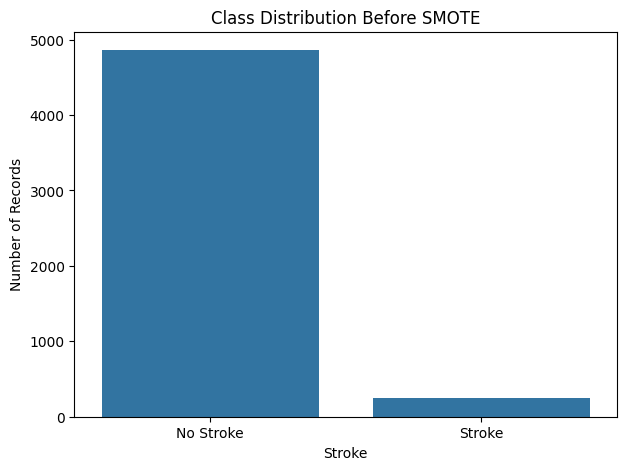

In [4]:
plt.figure(figsize=(7,5))

sns.countplot(
    x='stroke',
    data=df
)

plt.title('Class Distribution Before SMOTE')
plt.xlabel('Stroke')
plt.ylabel('Number of Records')

plt.xticks([0, 1], ['No Stroke', 'Stroke'])

plt.show()

In [5]:
X = df.drop('stroke', axis=1)

y = df['stroke']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (5110, 10)
Target Shape: (5110,)


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

Training Data: (4088, 10)
Testing Data: (1022, 10)

Training Class Distribution:
stroke
0    3889
1     199
Name: count, dtype: int64

Testing Class Distribution:
stroke
0    972
1     50
Name: count, dtype: int64


In [7]:
smote = SMOTE(
    sampling_strategy='auto',
    random_state=42,
    k_neighbors=5
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

print("\nBalanced Training Dataset Shape:")
print(X_train_smote.shape)

Before SMOTE:
stroke
0    3889
1     199
Name: count, dtype: int64

After SMOTE:
stroke
0    3889
1    3889
Name: count, dtype: int64

Balanced Training Dataset Shape:
(7778, 10)


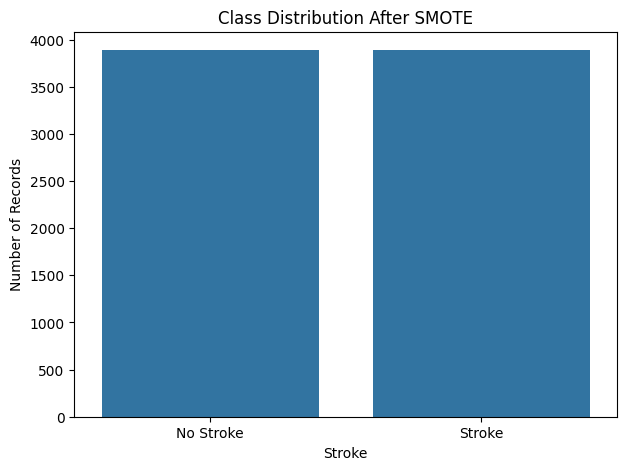

In [8]:
plt.figure(figsize=(7,5))

sns.countplot(
    x=y_train_smote
)

plt.title('Class Distribution After SMOTE')
plt.xlabel('Stroke')
plt.ylabel('Number of Records')

plt.xticks([0, 1], ['No Stroke', 'Stroke'])

plt.show()

In [9]:
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    'Decision Tree': DecisionTreeClassifier(
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    'Support Vector Machine (SVM)': SVC(
        kernel='rbf',
        probability=True,
        random_state=42
    ),

    'K-Nearest Neighbors (KNN)': KNeighborsClassifier(
        n_neighbors=5
    ),

    'Artificial Neural Network (ANN)': MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation='relu',
        solver='adam',
        max_iter=500,
        early_stopping=True,
        random_state=42
    )
}

print("All six classifiers defined successfully!")

All six classifiers defined successfully!


In [10]:
results = []

scaled_models = [
    'Logistic Regression',
    'Support Vector Machine (SVM)',
    'K-Nearest Neighbors (KNN)',
    'Artificial Neural Network (ANN)'
]

for name, classifier in models.items():

    for dataset_type in ['Original', 'SMOTE']:

        if dataset_type == 'Original':

            X_train_data = X_train
            y_train_data = y_train

        else:

            X_train_data = X_train_smote
            y_train_data = y_train_smote

        steps = []

        if dataset_type == 'SMOTE':
            steps.append(('smote', SMOTE(
                random_state=42,
                k_neighbors=5
            )))

        if name in scaled_models:
            steps.append(('scaler', StandardScaler()))

        steps.append(('classifier', classifier))

        model = Pipeline(steps)

        model.fit(X_train, y_train) if dataset_type == 'Original' else model.fit(X_train, y_train)

        # For the SMOTE case, SMOTE is performed inside the pipeline.
        # For the original case, no SMOTE is performed.

        y_pred = model.predict(X_test)

        y_prob = model.predict_proba(X_test)[:, 1]

        accuracy = accuracy_score(y_test, y_pred)

        precision = precision_score(
            y_test, y_pred, zero_division=0
        )

        recall = recall_score(
            y_test, y_pred, zero_division=0
        )

        f1 = f1_score(
            y_test, y_pred, zero_division=0
        )

        auc = roc_auc_score(y_test, y_prob)

        results.append({
            'Model': name,
            'Dataset': dataset_type,
            'Precision': precision,
            'Recall': recall,
            'F1-Score': f1,
            'Accuracy': accuracy,
            'AUC-ROC': auc
        })

        if dataset_type == 'SMOTE':

            print("\nModel:", name)

            print("Accuracy:", round(accuracy, 4))
            print("Precision:", round(precision, 4))
            print("Recall:", round(recall, 4))
            print("F1-Score:", round(f1, 4))
            print("AUC-ROC:", round(auc, 4))

print("\nAll models trained and evaluated successfully!")


Model: Logistic Regression
Accuracy: 0.7593
Precision: 0.1423
Recall: 0.78
F1-Score: 0.2407
AUC-ROC: 0.8219

Model: Decision Tree
Accuracy: 0.8601
Precision: 0.0957
Recall: 0.22
F1-Score: 0.1333
AUC-ROC: 0.5565

Model: Random Forest
Accuracy: 0.8845
Precision: 0.1304
Recall: 0.24
F1-Score: 0.169
AUC-ROC: 0.7757

Model: Support Vector Machine (SVM)
Accuracy: 0.7642
Precision: 0.1134
Recall: 0.56
F1-Score: 0.1886
AUC-ROC: 0.7532

Model: K-Nearest Neighbors (KNN)
Accuracy: 0.7847
Precision: 0.0913
Recall: 0.38
F1-Score: 0.1473
AUC-ROC: 0.6524

Model: Artificial Neural Network (ANN)
Accuracy: 0.8337
Precision: 0.1104
Recall: 0.34
F1-Score: 0.1667
AUC-ROC: 0.7615

All models trained and evaluated successfully!



Confusion Matrix: Logistic Regression
[[737 235]
 [ 11  39]]


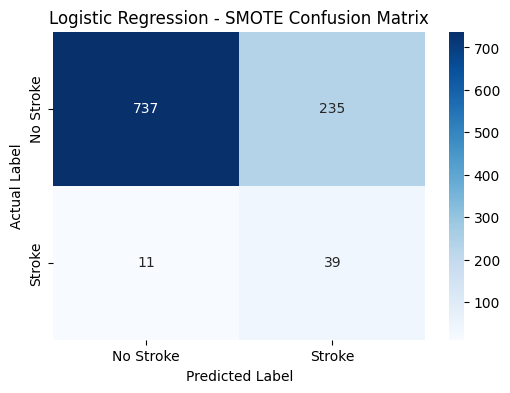


Confusion Matrix: Decision Tree
[[868 104]
 [ 39  11]]


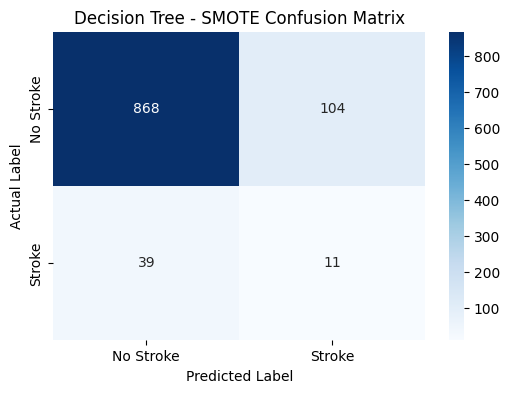


Confusion Matrix: Random Forest
[[892  80]
 [ 38  12]]


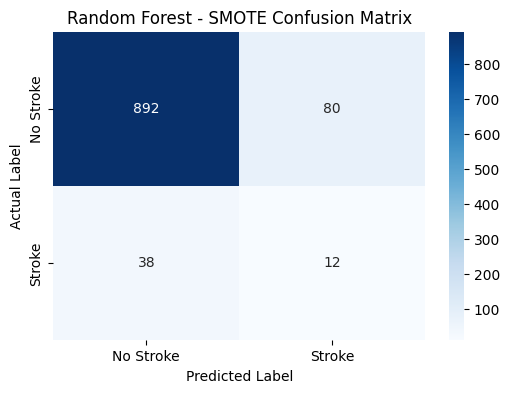


Confusion Matrix: Support Vector Machine (SVM)
[[753 219]
 [ 22  28]]


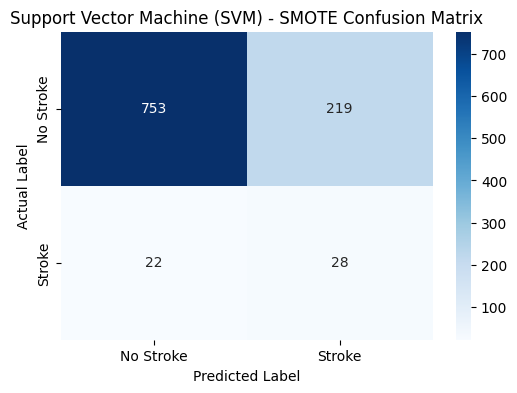


Confusion Matrix: K-Nearest Neighbors (KNN)
[[783 189]
 [ 31  19]]


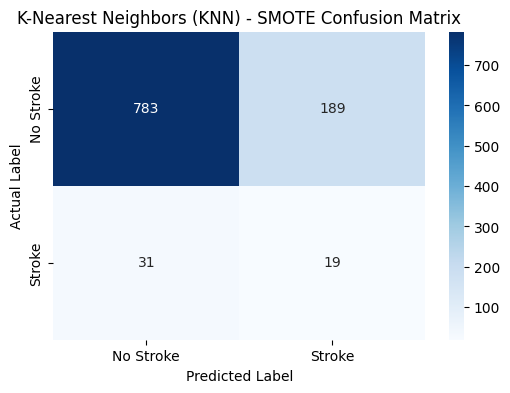


Confusion Matrix: Artificial Neural Network (ANN)
[[835 137]
 [ 33  17]]


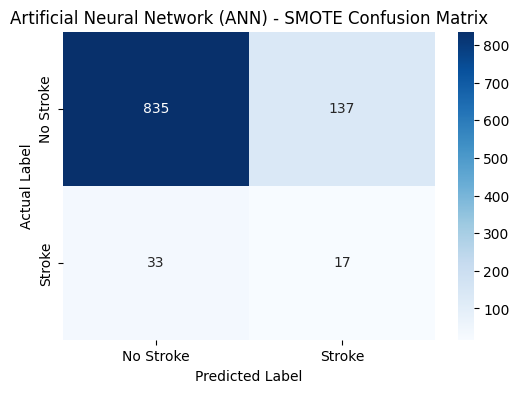

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay

smote_confusion_matrices = {}

for name, classifier in models.items():

    steps = []

    steps.append(('smote', SMOTE(
        random_state=42,
        k_neighbors=5
    )))

    if name in scaled_models:
        steps.append(('scaler', StandardScaler()))

    steps.append(('classifier', classifier))

    model = Pipeline(steps)

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    smote_confusion_matrices[name] = cm

    print("\nConfusion Matrix:", name)
    print(cm)

    plt.figure(figsize=(6, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['No Stroke', 'Stroke'],
        yticklabels=['No Stroke', 'Stroke']
    )

    plt.title(name + ' - SMOTE Confusion Matrix')
    plt.xlabel('Predicted Label')
    plt.ylabel('Actual Label')

    plt.show()

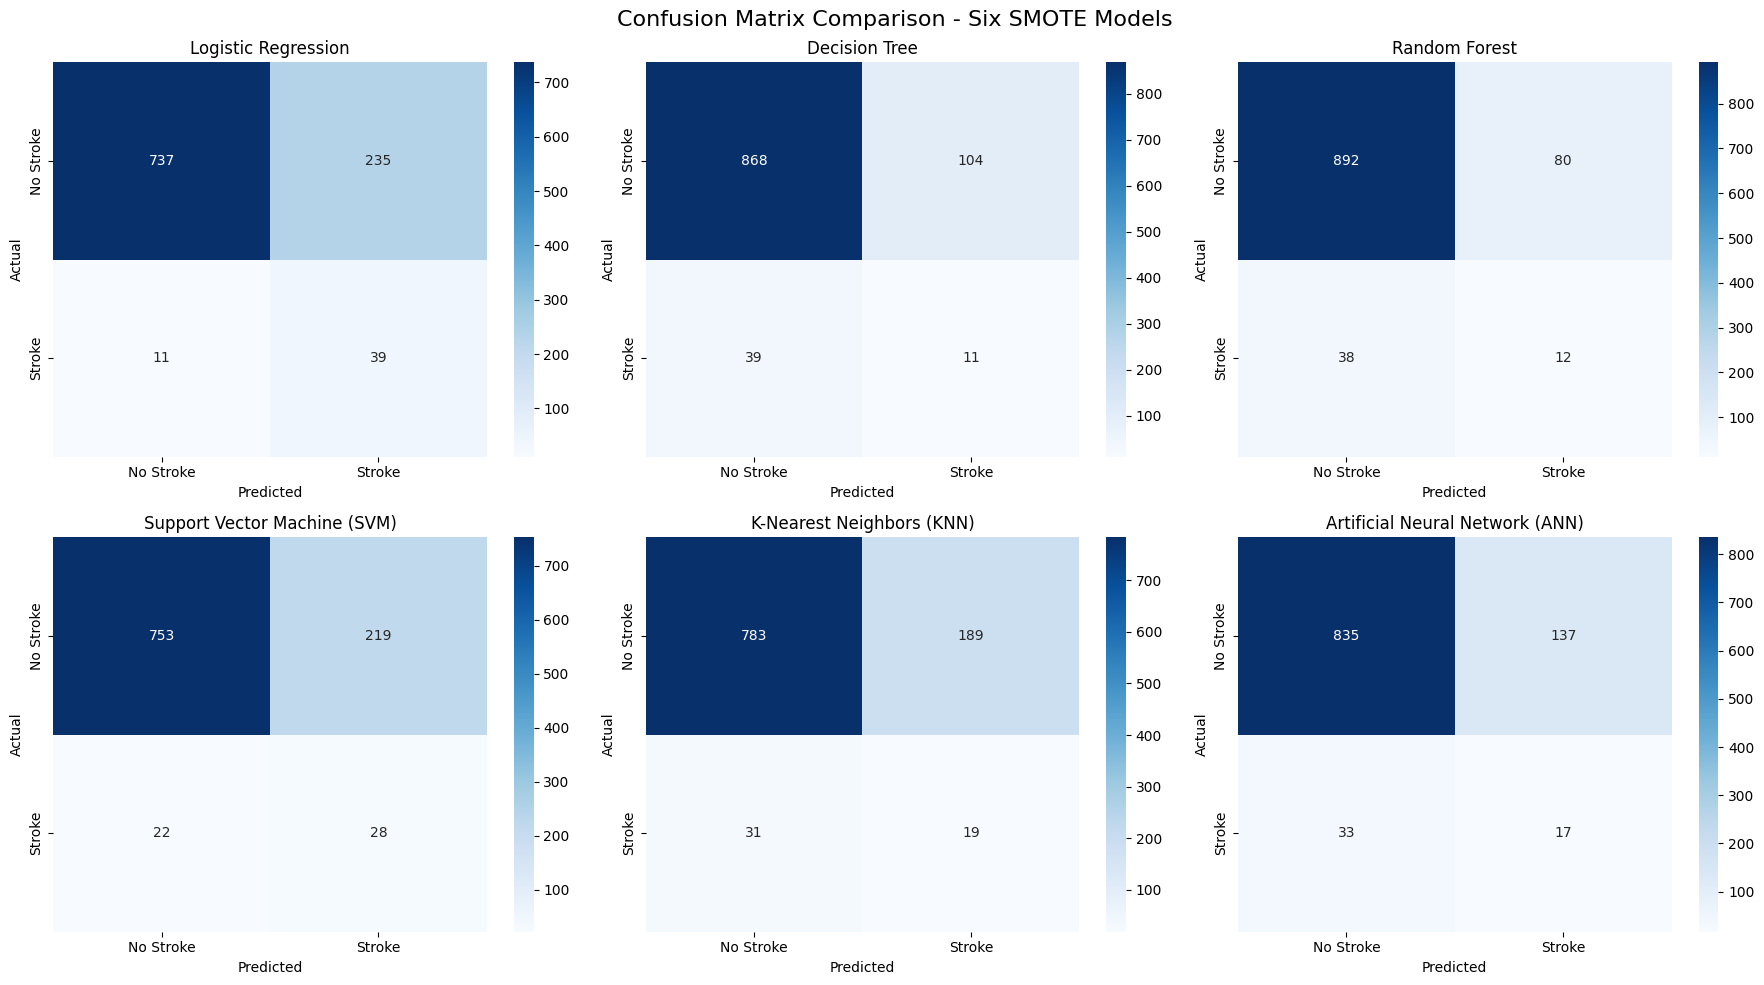

In [12]:
fig, axes = plt.subplots(
    2, 3,
    figsize=(18, 10)
)

for ax, (name, cm) in zip(
    axes.flatten(),
    smote_confusion_matrices.items()
):

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['No Stroke', 'Stroke'],
        yticklabels=['No Stroke', 'Stroke'],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.suptitle(
    'Confusion Matrix Comparison - Six SMOTE Models',
    fontsize=16
)

plt.tight_layout()
plt.show()

In [13]:
results_df = pd.DataFrame(results)

print("Comparative Performance of All Six Models")

display(
    results_df.style.format({
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1-Score': '{:.4f}',
        'Accuracy': '{:.4f}',
        'AUC-ROC': '{:.4f}'
    })
)

Comparative Performance of All Six Models


,Model,Dataset,Precision,Recall,F1-Score,Accuracy,AUC-ROC
0,Logistic Regression,Original,0.0000,0.0000,0.0000,0.9511,0.8377
1,Logistic Regression,SMOTE,0.1423,0.7800,0.2407,0.7593,0.8219
2,Decision Tree,Original,0.1667,0.1800,0.1731,0.9159,0.5669
3,Decision Tree,SMOTE,0.0957,0.2200,0.1333,0.8601,0.5565
4,Random Forest,Original,0.0000,0.0000,0.0000,0.9491,0.8135
5,Random Forest,SMOTE,0.1304,0.2400,0.1690,0.8845,0.7757
6,Support Vector Machine (SVM),Original,0.0000,0.0000,0.0000,0.9511,0.6108
7,Support Vector Machine (SVM),SMOTE,0.1134,0.5600,0.1886,0.7642,0.7532
8,K-Nearest Neighbors (KNN),Original,0.2000,0.0200,0.0364,0.9481,0.6140
9,K-Nearest Neighbors (KNN),SMOTE,0.0913,0.3800,0.1473,0.7847,0.6524


<Figure size 1400x700 with 0 Axes>

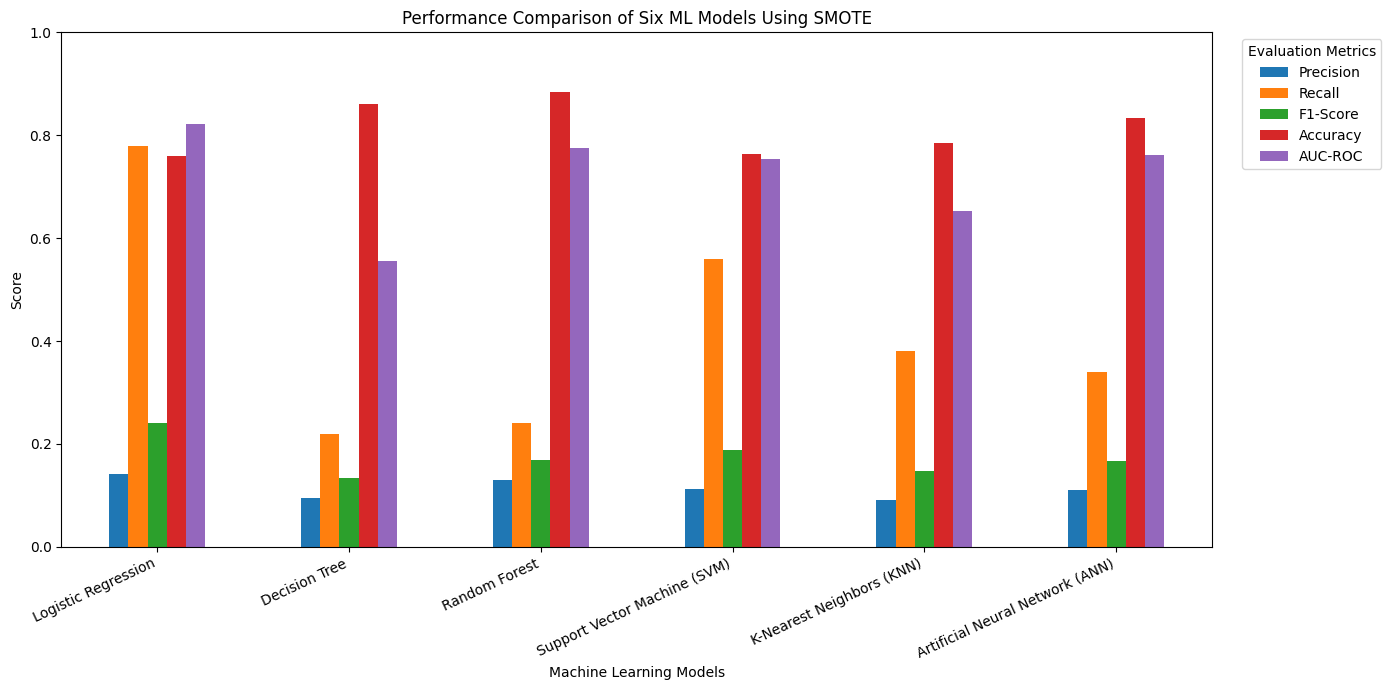

In [14]:
metrics = [
    'Precision',
    'Recall',
    'F1-Score',
    'Accuracy',
    'AUC-ROC'
]

smote_results = results_df[
    results_df['Dataset'] == 'SMOTE'
]

plt.figure(figsize=(14, 7))

smote_plot = smote_results.set_index('Model')[metrics]

ax = smote_plot.plot(
    kind='bar',
    figsize=(14, 7)
)

plt.title(
    'Performance Comparison of Six ML Models Using SMOTE'
)

plt.xlabel('Machine Learning Models')
plt.ylabel('Score')

plt.ylim(0, 1)

plt.xticks(rotation=25, ha='right')

plt.legend(
    title='Evaluation Metrics',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()

In [15]:
top_3 = smote_results.sort_values(
    by=['F1-Score', 'AUC-ROC', 'Recall'],
    ascending=False
).head(3)

print("TOP 3 PERFORMING MODELS")

display(
    top_3.style.format({
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1-Score': '{:.4f}',
        'Accuracy': '{:.4f}',
        'AUC-ROC': '{:.4f}'
    })
)

TOP 3 PERFORMING MODELS


,Model,Dataset,Precision,Recall,F1-Score,Accuracy,AUC-ROC
1,Logistic Regression,SMOTE,0.1423,0.7800,0.2407,0.7593,0.8219
7,Support Vector Machine (SVM),SMOTE,0.1134,0.5600,0.1886,0.7642,0.7532
5,Random Forest,SMOTE,0.1304,0.2400,0.1690,0.8845,0.7757


In [16]:
comparison = results_df.pivot(
    index='Model',
    columns='Dataset',
    values=['Precision', 'Recall', 'F1-Score',
            'Accuracy', 'AUC-ROC']
)

print("Original vs SMOTE Performance Comparison")

display(comparison.round(4))

Original vs SMOTE Performance Comparison


Precision           Recall       F1-Score  \
Dataset                          Original   SMOTE Original SMOTE Original   
Model                                                                       
Artificial Neural Network (ANN)    0.0000  0.1104     0.00  0.34   0.0000   
Decision Tree                      0.1667  0.0957     0.18  0.22   0.1731   
K-Nearest Neighbors (KNN)          0.2000  0.0913     0.02  0.38   0.0364   
Logistic Regression                0.0000  0.1423     0.00  0.78   0.0000   
Random Forest                      0.0000  0.1304     0.00  0.24   0.0000   
Support Vector Machine (SVM)       0.0000  0.1134     0.00  0.56   0.0000   

                                        Accuracy          AUC-ROC          
Dataset                           SMOTE Original   SMOTE Original   SMOTE  
Model                                                                      
Artificial Neural Network (ANN)  0.1667   0.9511  0.8337   0.5410  0.7615  
Decision Tree                    0.1333   0.9159  0.8601   0.5669  0.5565  
K-Nearest Neighbors (KNN)        0.1473   0.9481  0.7847   0.6140  0.6524  
Logistic Regression              0.2407   0.9511  0.7593   0.8377  0.8219  
Random Forest                    0.1690   0.9491  0.8845   0.8135  0.7757  
Support Vector Machine (SVM)     0.1886   0.9511  0.7642   0.6108  0.7532

In [17]:
# Save comparative results
results_df.to_csv(
    'stroke_comparative_results.csv',
    index=False
)

# Save top three models
top_3.to_csv(
    'stroke_top_3_models.csv',
    index=False
)

print("Files saved successfully!")

from google.colab import files

files.download('stroke_comparative_results.csv')
files.download('stroke_top_3_models.csv')

Files saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>